In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("/content/organics.csv")

In [3]:
df.head(10)

,Customer Loyalty ID,Gender,Geographic Region,Loyalty Status,Neigborhood Cluster-55 Level,Neighborhood Cluster-7 Level,Television Region,Affluence Grade,Age,Frequency,Frequency Percent,Loyalty Card Tenure,Organics Purchase Count,Organics Purchase Indicator,Total Spend
0,140,U,Midlands,Gold,16.0,C,Wales & West,10,76,1,0.00%,4,0,0,16000.00
1,620,U,Midlands,Gold,35.0,D,Wales & West,4,49,1,0.00%,5,0,0,6000.00
2,868,F,Midlands,Silver,27.0,D,Wales & West,5,70,1,0.00%,8,1,1,0.02
3,1120,M,Midlands,Tin,51.0,F,Midlands,10,65,1,0.00%,7,1,1,0.01
4,2313,F,Midlands,Tin,4.0,A,Midlands,11,68,1,0.00%,8,0,0,0.01
5,2771,U,North,Platinum,28.0,D,N West,9,72,1,0.00%,3,0,0,20759.81
6,3131,F,Midlands,Tin,3.0,A,East,11,74,1,0.00%,8,0,0,0.01
7,3328,M,North,Tin,32.0,D,N East,13,62,1,0.00%,5,0,0,0.01
8,4529,M,Midlands,Silver,49.0,F,East,10,62,1,0.00%,3,0,0,2038.76
9,5886,F,NaN,Gold,49.0,F,NaN,14,43,1,0.00%,1,1,1,6000.00


In [4]:
# Clean numeric data (handle missing values).
df_clean = df.copy()
df_clean['Age'] = pd.to_numeric(df_clean['Age'], errors='coerce')
df_clean['Organics Purchase Count'] = pd.to_numeric(df_clean['Organics Purchase Count'], errors='coerce')
df_clean['Total Spend'] = pd.to_numeric(df_clean['Total Spend'], errors='coerce')
df_clean['Loyalty Card Tenure'] = pd.to_numeric(df_clean['Loyalty Card Tenure'], errors='coerce')
df_clean['Affluence Grade'] = pd.to_numeric(df_clean['Affluence Grade'], errors='coerce')


In [13]:
from pandas.core.tools import numeric
# limit dataset to only include datapoints where loyalty card tenure >= 1
df_clean = df_clean[df_clean['Loyalty Card Tenure'] >= 1]

# convert Categorical variables (Gender, Geographic Region, Loyalty Status) using One-Hot Encoding
categorical_cols = ['Gender', 'Geographic Region', 'Loyalty Status']
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# drop features with redundancy or constancy
data=data.drop(columns=['Customer Loyalty ID','Neighborhood Cluster-7 Level','Frequency','Frequency Percent'] )

# drop rows with NaN in the core numeric columns we want to evaluate
numeric_cols = ['Age', 'Organics Purchase Count', 'Total Spend', 'Affluence Grade']
data = df_encoded.dropna(subset=numeric_cols)

print(f"Final clean dataset contains {data.shape[0]} rows.")

Final clean dataset contains 19426 rows.


In [6]:
# check to make sure non-loyalty members were dropped.
data['Loyalty Card Tenure'].value_counts()


,count
Loyalty Card Tenure,
5.0,3674
8.0,2779
4.0,2246
1.0,1377
9.0,1376
2.0,1322
7.0,1170
6.0,993
3.0,917


In [17]:
# examine new columns and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19426 entries, 0 to 22222
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Neigborhood Cluster-55 Level  18859 non-null  float64
 1   Television Region             19021 non-null  object 
 2   Affluence Grade               19426 non-null  float64
 3   Age                           19426 non-null  float64
 4   Loyalty Card Tenure           19426 non-null  float64
 5   Organics Purchase Count       19426 non-null  int64  
 6   Organics Purchase Indicator   19426 non-null  int64  
 7   Total Spend                   19426 non-null  float64
 8   Gender_M                      19426 non-null  bool   
 9   Gender_U                      19426 non-null  bool   
 10  Geographic Region_North       19426 non-null  bool   
 11  Geographic Region_Scottish    19426 non-null  bool   
 12  Geographic Region_South East  19426 non-null  bool   
 13  Geogra

In [19]:
# get value counts for object and boolean features
print(data['Television Region'].value_counts())
print(data['Organics Purchase Count'].value_counts())
print(data['Organics Purchase Indicator'].value_counts())
print(data['Gender_M'].value_counts())
print(data['Gender_U'].value_counts())
print(data['Geographic Region_North'].value_counts())
print(data['Geographic Region_Scottish'].value_counts())
print(data['Geographic Region_South East'].value_counts())
print(data['Geographic Region_South West'].value_counts())
print(data['Loyalty Status_Platinum'].value_counts())
print(data['Loyalty Status_Silver'].value_counts())
print(data['Loyalty Status_Tin'].value_counts())

# drop organics purchase count as it is redundant and similar in nature to the target variable
# drop gender_u as it measures unknown gender, and Gender_M contains the full dataset for M/F-labeled customers
data = data.drop(columns=['Gender_U','Organics Purchase Count'])


Television Region
London          5370
Midlands        2755
S & S East      2134
N West          1833
Wales & West    1501
East            1434
Yorkshire       1253
C Scotland       736
N East           695
S West           616
N Scot           293
Ulster           226
Border           175
Name: count, dtype: int64
Organics Purchase Count
0    14669
1     4002
2      617
3      138
Name: count, dtype: int64
Organics Purchase Indicator
0    14669
1     4757
Name: count, dtype: int64
Gender_M
False    14359
True      5067
Name: count, dtype: int64
Gender_U
False    17886
True      1540
Name: count, dtype: int64
Geographic Region_North
False    15645
True      3781
Name: count, dtype: int64
Geographic Region_Scottish
False    18222
True      1204
Name: count, dtype: int64
Geographic Region_South East
False    11922
True      7504
Name: count, dtype: int64
Geographic Region_South West
False    18810
True       616
Name: count, dtype: int64
Loyalty Status_Platinum
False    18684
True       

In [20]:
# get descriptive statistics for all numeric features
data.describe()

,Neigborhood Cluster-55 Level,Affluence Grade,Age,Loyalty Card Tenure,Organics Purchase Indicator,Total Spend
count,18859.000000,19426.000000,19426.000000,19426.000000,19426.000000,19426.000000
mean,27.206692,8.705446,53.837846,6.566200,0.244878,4456.518347
std,15.751080,3.423340,13.190487,4.637575,0.430026,7690.317173
min,1.000000,0.000000,18.000000,1.000000,0.000000,0.010000
25%,14.000000,6.000000,44.000000,4.000000,0.000000,0.010000
50%,27.000000,8.000000,54.000000,5.000000,0.000000,2000.000000
75%,38.000000,11.000000,64.000000,8.000000,0.000000,6000.000000
max,55.000000,34.000000,79.000000,39.000000,1.000000,296313.850000


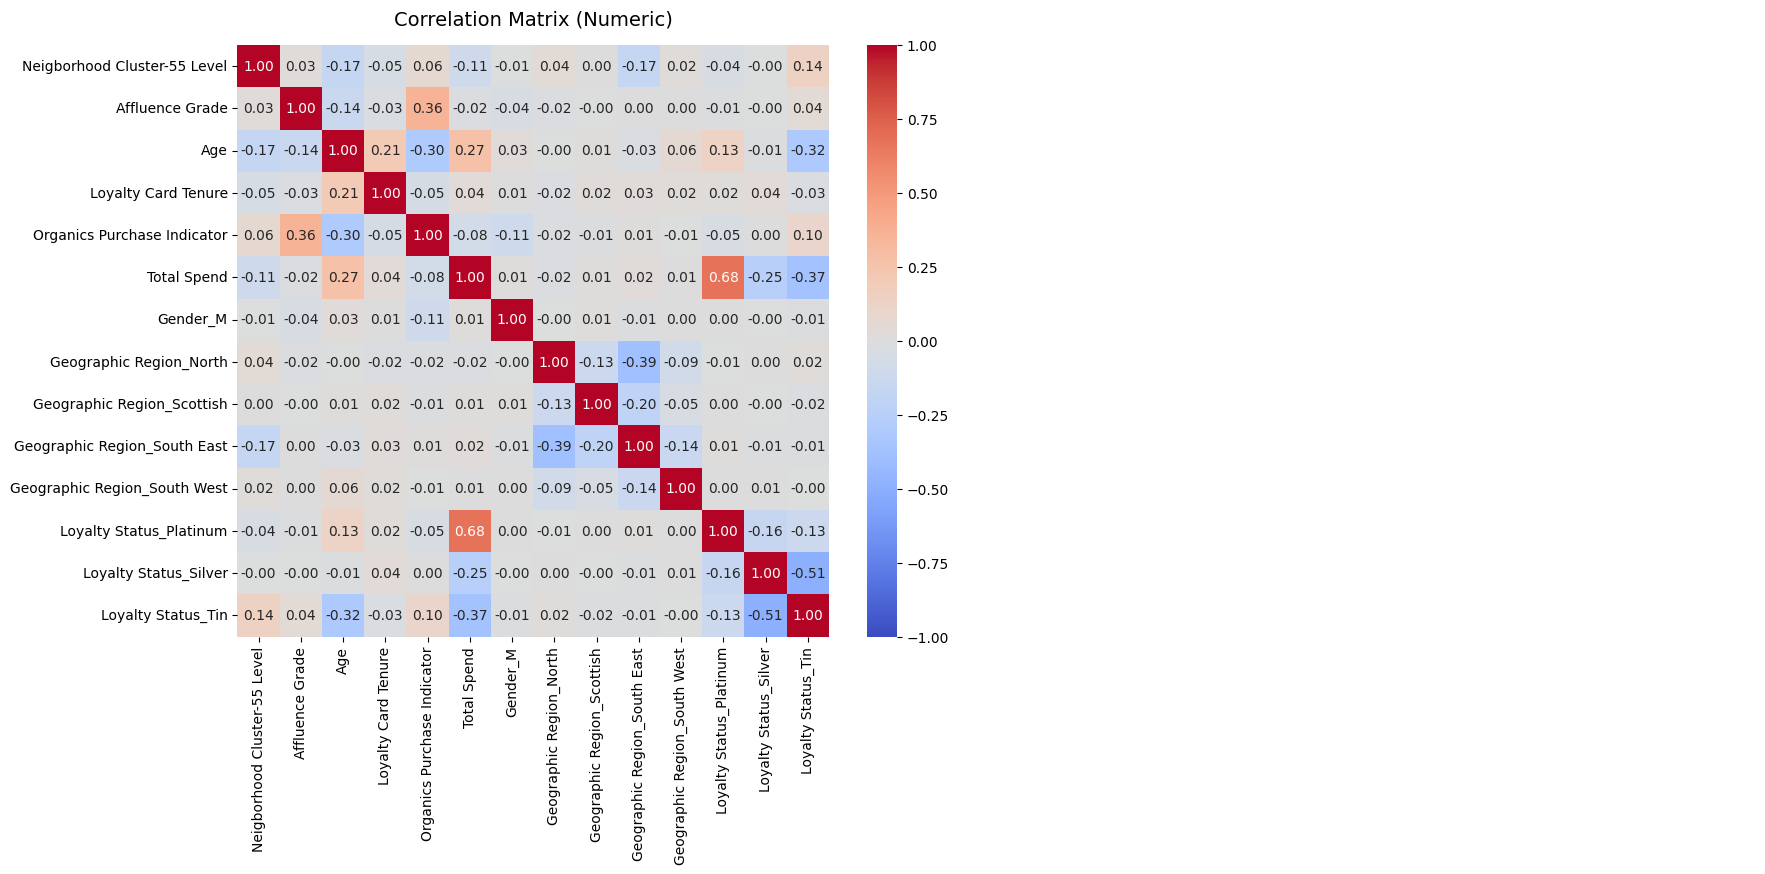

In [40]:
# Select numeric and boolean columns, converting booleans to float/int
numeric_df = data.select_dtypes(include=['number', 'bool']).astype(float)

# Calculate correlation matrix with Organics Purchase Indicator
correlations = numeric_df.corr(method='pearson')['Organics Purchase Indicator'].sort_values(ascending=False)

# plt.subplots(1, 2) returns a NumPy array containing [ax[0], ax[1]]
fig, ax = plt.subplots(1, 2, figsize=(18, 8))

corr_matrix = numeric_df.corr()

# Fix: Pass the first axis element ax[0] instead of the whole NumPy array ax
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1, vmax=1,
    ax=ax[0],
    square=True
)

# 5. Format and display on the specific axis
ax[0].set_title('Correlation Matrix (Numeric)', fontsize=14, pad=15)

# Turn off the second unused subplot axis
ax[1].axis('off')

plt.tight_layout()
plt.show()
# Display the correlation values
# print("Correlation of all features with 'Organics Purchase Indicator':")
#display(correlations)

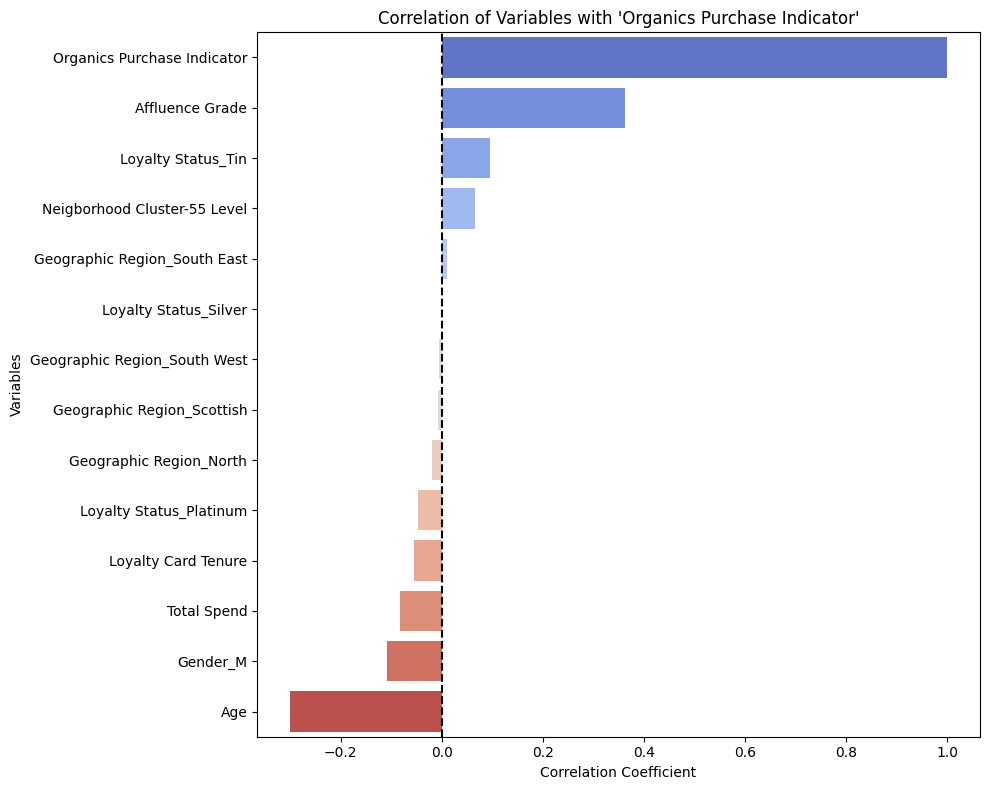

In [41]:
# Plot the correlations with 'Organics Purchase Indicator'
plt.figure(figsize=(10, 8))
sns.barplot(x=correlations.values, y=correlations.index, hue=correlations.index, palette='coolwarm', legend=False)
plt.title("Correlation of Variables with 'Organics Purchase Indicator'")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Variables")
plt.axvline(x=0, color='black', linestyle='--')
plt.tight_layout()
plt.show()

In [45]:
# Geographic Region_Scottish, South West, Loyalty_Status Silver,and Geographic Region South_East all have insignificant correlation to the target variable
# Non-correlated features dropped
reduced1_data = data.drop(columns=['Geographic Region_Scottish','Geographic Region_South West','Geographic Region_South East','Loyalty Status_Silver'])


In [51]:
# Define X and Y variables for model creation and fitting
X = reduced1_data[['Age', 'Gender_M', 'Total Spend', 'Loyalty Card Tenure', 'Loyalty Status_Platinum', 'Geographic Region_North', 'Neigborhood Cluster-55 Level', 'Loyalty Status_Tin', 'Affluence Grade']]
Y = reduced1_data['Organics Purchase Indicator']